In [1]:
print("Welcome to my Customer Churn Prediction Project!")

Welcome to my Customer Churn Prediction Project!


In [2]:
import pandas as pd

file_path = "data/archive/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print("Dataset shape:", df.shape)

Dataset shape: (7043, 21)


In [5]:
df.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [6]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
# Count missing values in each column
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
# Check missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Check blank or whitespace-only TotalCharges values
print("\nBlank TotalCharges values:")
print(df["TotalCharges"].str.strip().eq("").sum())

# Check exact duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Blank TotalCharges values:
11

Duplicate rows: 0


In [11]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("Data type:", df["TotalCharges"].dtype)
print("Missing values:", df["TotalCharges"].isnull().sum())

Data type: float64
Missing values: 11


In [12]:
df.loc[
    df["TotalCharges"].isnull(),
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [13]:
print("Rows with missing TotalCharges:")
print(df[df["TotalCharges"].isnull()].shape[0])

print("\nTenure values for these rows:")
print(df.loc[df["TotalCharges"].isnull(), "tenure"].value_counts())

print("\nChurn values for these rows:")
print(df.loc[df["TotalCharges"].isnull(), "Churn"].value_counts())

Rows with missing TotalCharges:
11

Tenure values for these rows:
tenure
0    11
Name: count, dtype: int64

Churn values for these rows:
Churn
No    11
Name: count, dtype: int64


In [14]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Missing TotalCharges after cleaning:",
      df["TotalCharges"].isnull().sum())

print("TotalCharges data type:",
      df["TotalCharges"].dtype)

Missing TotalCharges after cleaning: 0
TotalCharges data type: float64


In [15]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values in dataset:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nDataset shape:")
print(df.shape)

Missing values in each column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Total missing values in dataset:
0

Duplicate rows:
0

Dataset shape:
(7043, 21)


In [16]:
print("Customer churn distribution:")
print(df["Churn"].value_counts())

print("\nCustomer churn percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

Customer churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Customer churn percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


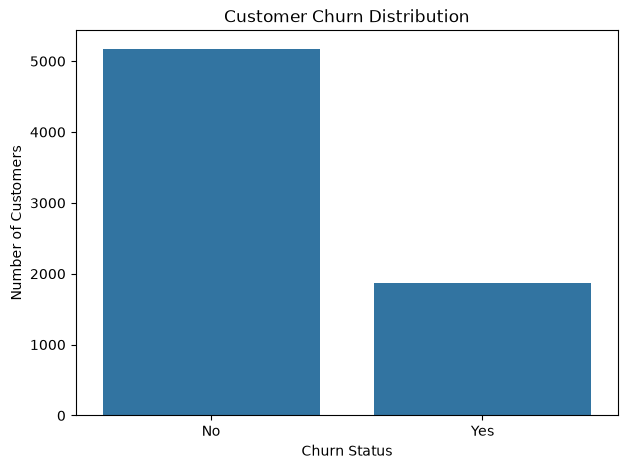

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

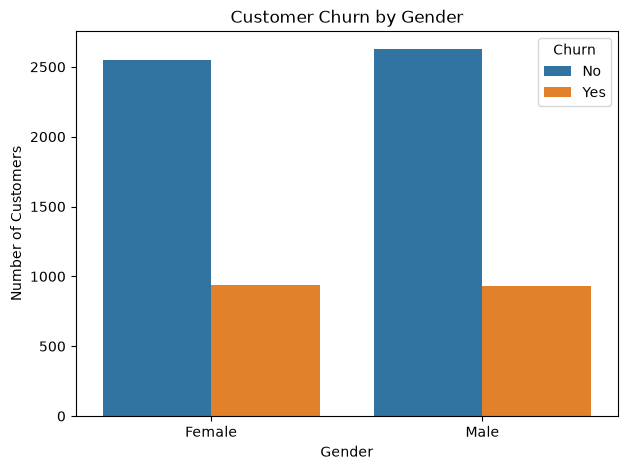

In [18]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="gender", hue="Churn")

plt.title("Customer Churn by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

plt.show()

In [19]:
gender_churn_rate = pd.crosstab(
    df["gender"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn rate by gender (%):")
print(gender_churn_rate.round(2))

Churn rate by gender (%):
Churn      No    Yes
gender              
Female  73.08  26.92
Male    73.84  26.16


In [20]:
contract_churn_rate = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn rate by contract type (%):")
print(contract_churn_rate.round(2))

Churn rate by contract type (%):
Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


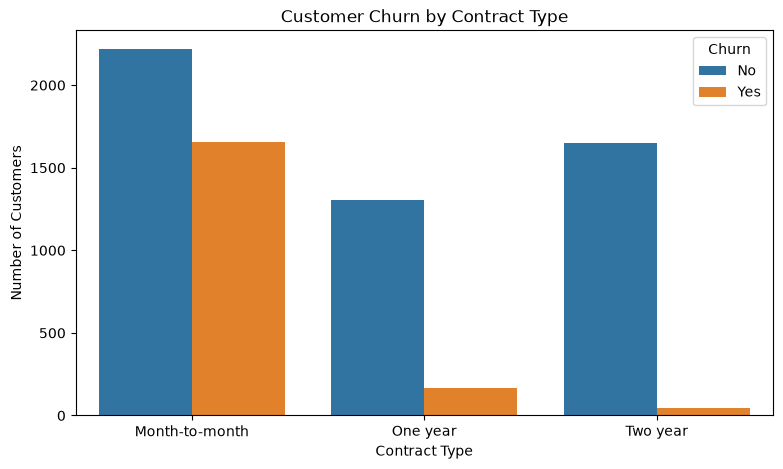

In [21]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

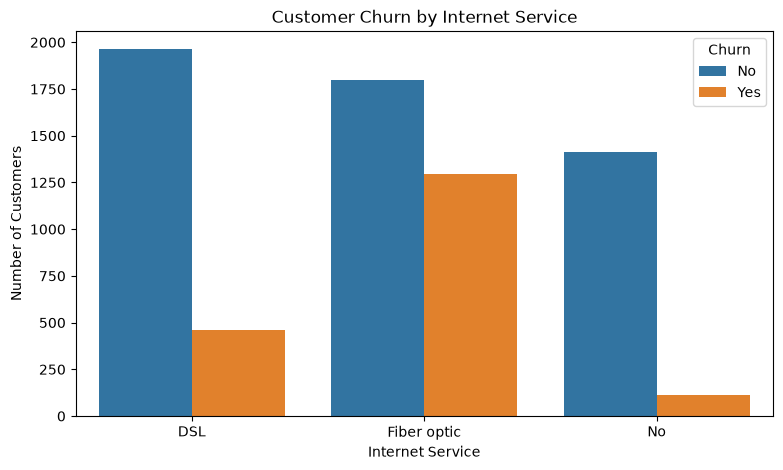

In [22]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="InternetService", hue="Churn")

plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

In [23]:
internet_churn_rate = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn rate by Internet Service (%):")
print(internet_churn_rate.round(2))

Churn rate by Internet Service (%):
Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40


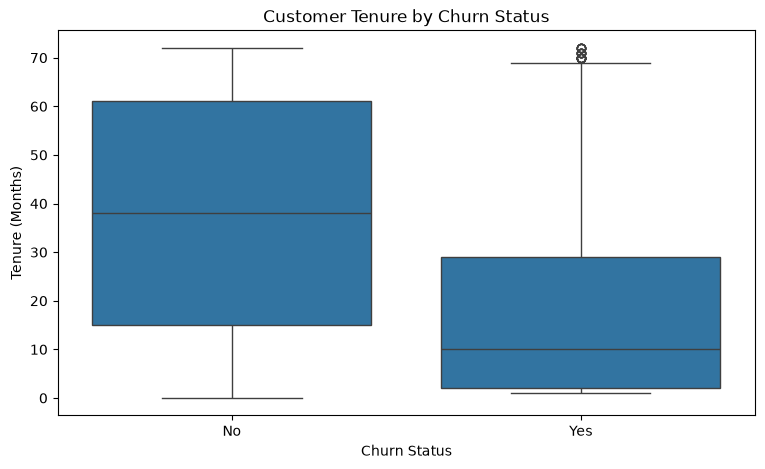

In [24]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="Churn", y="tenure")

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")

plt.show()

In [25]:
print("Median tenure by churn status:")
print(df.groupby("Churn")["tenure"].median())

print("\nAverage tenure by churn status:")
print(df.groupby("Churn")["tenure"].mean().round(2))

Median tenure by churn status:
Churn
No     38.0
Yes    10.0
Name: tenure, dtype: float64

Average tenure by churn status:
Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64


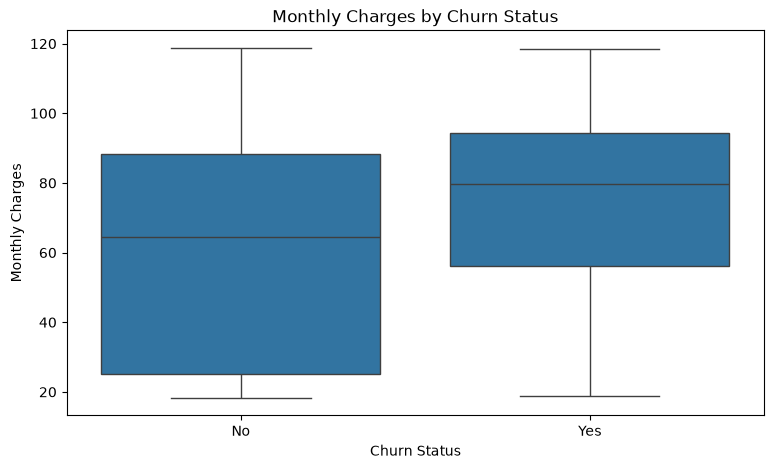

In [26]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")

plt.show()

In [27]:
print("Median monthly charges by churn status:")
print(df.groupby("Churn")["MonthlyCharges"].median())

print("\nAverage monthly charges by churn status:")
print(df.groupby("Churn")["MonthlyCharges"].mean().round(2))

Median monthly charges by churn status:
Churn
No     64.425
Yes    79.650
Name: MonthlyCharges, dtype: float64

Average monthly charges by churn status:
Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


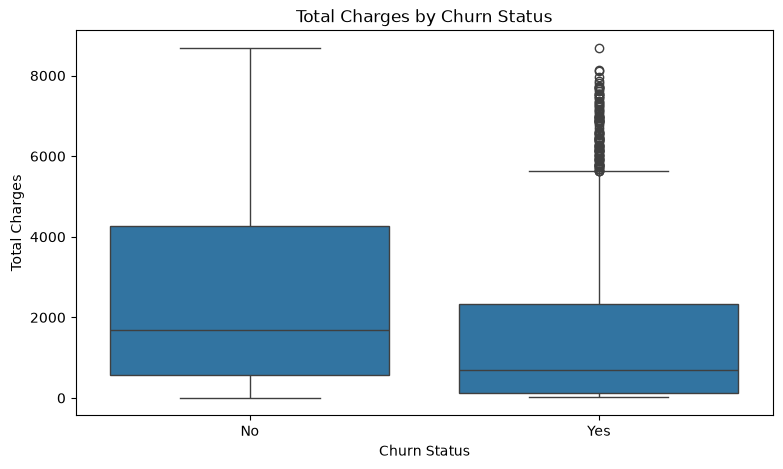

In [28]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="Churn", y="TotalCharges")

plt.title("Total Charges by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Total Charges")

plt.show()

In [29]:
print("Median total charges by churn status:")
print(df.groupby("Churn")["TotalCharges"].median())

print("\nAverage total charges by churn status:")
print(df.groupby("Churn")["TotalCharges"].mean().round(2))

Median total charges by churn status:
Churn
No     1679.525
Yes     703.550
Name: TotalCharges, dtype: float64

Average total charges by churn status:
Churn
No     2549.91
Yes    1531.80
Name: TotalCharges, dtype: float64


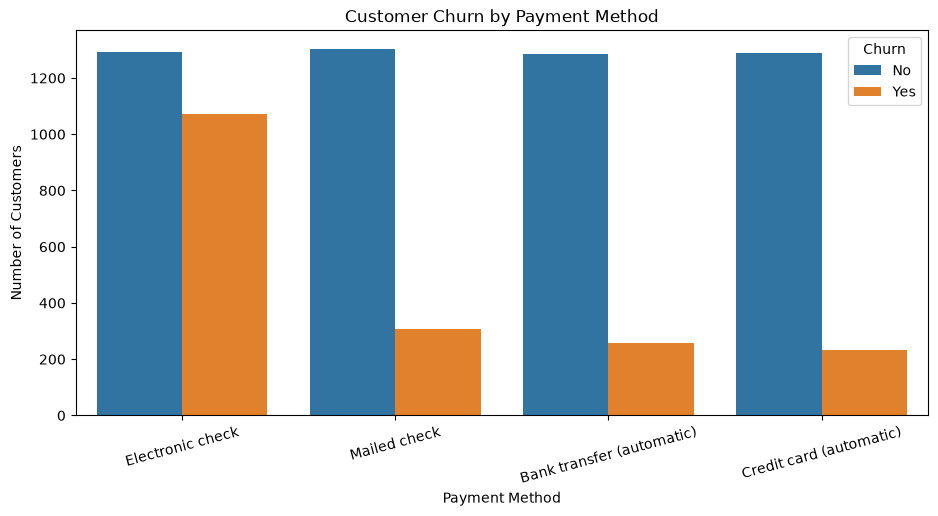

In [30]:
plt.figure(figsize=(11, 5))

sns.countplot(data=df, x="PaymentMethod", hue="Churn")

plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)

plt.show()

In [31]:
payment_churn_rate = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn rate by payment method (%):")
print(payment_churn_rate.round(2))

Churn rate by payment method (%):
Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11


In [32]:
security_churn_rate = pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn rate by Online Security (%):")
print(security_churn_rate.round(2))

Churn rate by Online Security (%):
Churn                   No    Yes
OnlineSecurity                   
No                   58.23  41.77
No internet service  92.60   7.40
Yes                  85.39  14.61


In [33]:
remaining_features = [
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "PaperlessBilling"
]

for feature in remaining_features:
    print(f"\n--- {feature} ---")

    rates = pd.crosstab(
        df[feature],
        df["Churn"],
        normalize="index"
    ) * 100

    print(rates.round(2))


--- Partner ---
Churn       No    Yes
Partner              
No       67.04  32.96
Yes      80.34  19.66

--- Dependents ---
Churn          No    Yes
Dependents              
No          68.72  31.28
Yes         84.55  15.45

--- PhoneService ---
Churn            No    Yes
PhoneService              
No            75.07  24.93
Yes           73.29  26.71

--- MultipleLines ---
Churn                No    Yes
MultipleLines                 
No                74.96  25.04
No phone service  75.07  24.93
Yes               71.39  28.61

--- OnlineBackup ---
Churn                   No    Yes
OnlineBackup                     
No                   60.07  39.93
No internet service  92.60   7.40
Yes                  78.47  21.53

--- DeviceProtection ---
Churn                   No    Yes
DeviceProtection                 
No                   60.87  39.13
No internet service  92.60   7.40
Yes                  77.50  22.50

--- TechSupport ---
Churn                   No    Yes
TechSupport             

In [34]:
# Feature 1: Average total charges per month of tenure
df["TotalChargesPerTenure"] = (
    df["TotalCharges"] / df["tenure"].replace(0, 1)
)

# Feature 2: Count additional services
service_columns = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

df["ServiceCount"] = (
    df[service_columns] == "Yes"
).sum(axis=1)

# Display the new features
print(df[["tenure", "TotalCharges", "TotalChargesPerTenure",
          "ServiceCount"]].head())

print("\nNew dataset shape:", df.shape)

   tenure  TotalCharges  TotalChargesPerTenure  ServiceCount
0       1         29.85              29.850000             1
1      34       1889.50              55.573529             2
2       2        108.15              54.075000             2
3      45       1840.75              40.905556             3
4       2        151.65              75.825000             0

New dataset shape: (7043, 23)


In [35]:
# Calculate the average charge only when tenure is greater than zero
df["TotalChargesPerTenure"] = (
    df["TotalCharges"] / df["tenure"].replace(0, float("nan"))
)

print("Missing values in TotalChargesPerTenure:",
      df["TotalChargesPerTenure"].isnull().sum())

print("\nZero-tenure customer count:",
      (df["tenure"] == 0).sum())

print("\nNew feature preview:")
print(df[["tenure", "TotalCharges",
          "TotalChargesPerTenure", "ServiceCount"]].head())

Missing values in TotalChargesPerTenure: 11

Zero-tenure customer count: 11

New feature preview:
   tenure  TotalCharges  TotalChargesPerTenure  ServiceCount
0       1         29.85              29.850000             1
1      34       1889.50              55.573529             2
2       2        108.15              54.075000             2
3      45       1840.75              40.905556             3
4       2        151.65              75.825000             0


In [36]:
df["HasMultipleServices"] = (
    df["ServiceCount"] >= 2
).astype(int)

print(df[[
    "ServiceCount",
    "HasMultipleServices"
]].head(10))

print("\nDataset shape:", df.shape)

   ServiceCount  HasMultipleServices
0             1                    0
1             2                    1
2             2                    1
3             3                    1
4             0                    0
5             3                    1
6             2                    1
7             1                    0
8             4                    1
9             2                    1

Dataset shape: (7043, 24)


In [37]:
from sklearn.model_selection import train_test_split

# Target: No = 0, Yes = 1
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].map({"No": 0, "Yes": 1})

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (5634, 22)
Testing features: (1409, 22)

Training target distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing target distribution:
Churn
0    1035
1     374
Name: count, dtype: int64


MODEL COMPARISON


,Accuracy,Precision,Recall,ROC-AUC
Model,,,,
Logistic Regression,0.743,0.510,0.791,0.842
Random Forest,0.759,0.541,0.612,0.822


<Figure size 800x600 with 0 Axes>

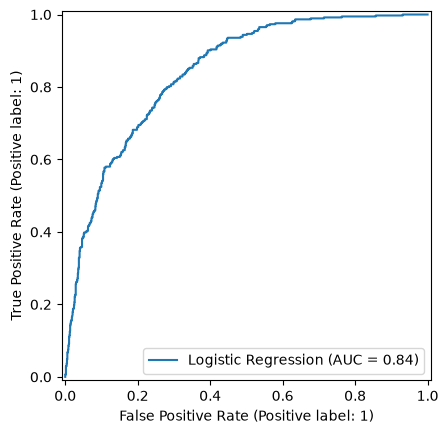

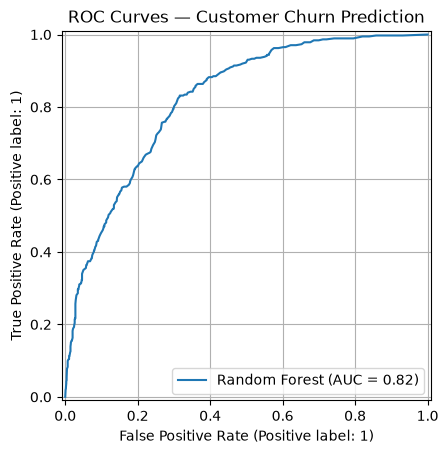

Best model by ROC-AUC: Logistic Regression

Confusion Matrix:


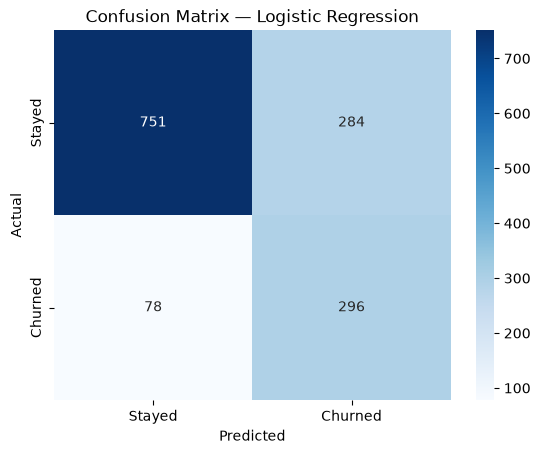

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    roc_auc_score, confusion_matrix, RocCurveDisplay
)

# Identify numeric and categorical columns
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Preprocessing for numeric features
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical features
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

# Models to compare
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    )
}

results = []
trained_models = {}

# Train and evaluate each model
for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

    trained_models[name] = pipeline

# Display model comparison
results_df = pd.DataFrame(results).set_index("Model")

print("MODEL COMPARISON")
display(results_df.round(3))

# Plot ROC curves
plt.figure(figsize=(8, 6))

for name, pipeline in trained_models.items():
    RocCurveDisplay.from_estimator(
        pipeline, X_test, y_test, name=name
    )

plt.title("ROC Curves — Customer Churn Prediction")
plt.grid(True)
plt.show()

# Plot confusion matrix for the model with the highest ROC-AUC
best_model_name = results_df["ROC-AUC"].idxmax()
best_model = trained_models[best_model_name]

best_predictions = best_model.predict(X_test)

print("Best model by ROC-AUC:", best_model_name)
print("\nConfusion Matrix:")

cm = confusion_matrix(y_test, best_predictions)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"]
)

plt.title(f"Confusion Matrix — {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [39]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.base import clone

# Tune the existing Logistic Regression pipeline
lr_pipeline = clone(trained_models["Logistic Regression"])

param_grid = {
    "model__C": [0.1, 1, 10],
    "model__solver": ["liblinear", "lbfgs"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best 5-fold CV ROC-AUC:", round(grid_search.best_score_, 4))

# Evaluate the tuned model on the held-out test set
tuned_model = grid_search.best_estimator_
test_probabilities = tuned_model.predict_proba(X_test)[:, 1]
test_predictions = tuned_model.predict(X_test)

from sklearn.metrics import (
    roc_auc_score, precision_score, recall_score, accuracy_score
)

print("\nTUNED MODEL — TEST RESULTS")
print("Accuracy:", round(accuracy_score(y_test, test_predictions), 3))
print("Precision:", round(precision_score(y_test, test_predictions), 3))
print("Recall:", round(recall_score(y_test, test_predictions), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, test_probabilities), 3))

Best parameters: {'model__C': 10, 'model__solver': 'lbfgs'}
Best 5-fold CV ROC-AUC: 0.8458

TUNED MODEL — TEST RESULTS
Accuracy: 0.739
Precision: 0.505
Recall: 0.786
ROC-AUC: 0.841


In [40]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.base import clone

# Tune the existing Logistic Regression pipeline
lr_pipeline = clone(trained_models["Logistic Regression"])

param_grid = {
    "model__C": [0.1, 1, 10],
    "model__solver": ["liblinear", "lbfgs"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best 5-fold CV ROC-AUC:", round(grid_search.best_score_, 4))

# Evaluate the tuned model on the held-out test set
tuned_model = grid_search.best_estimator_
test_probabilities = tuned_model.predict_proba(X_test)[:, 1]
test_predictions = tuned_model.predict(X_test)

from sklearn.metrics import (
    roc_auc_score, precision_score, recall_score, accuracy_score
)

print("\nTUNED MODEL — TEST RESULTS")
print("Accuracy:", round(accuracy_score(y_test, test_predictions), 3))
print("Precision:", round(precision_score(y_test, test_predictions), 3))
print("Recall:", round(recall_score(y_test, test_predictions), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, test_probabilities), 3))

Best parameters: {'model__C': 10, 'model__solver': 'lbfgs'}
Best 5-fold CV ROC-AUC: 0.8458

TUNED MODEL — TEST RESULTS
Accuracy: 0.739
Precision: 0.505
Recall: 0.786
ROC-AUC: 0.841


In [41]:
try:
    import xgboost
    print("XGBoost is installed.")
    print("Version:", xgboost.__version__)
except ImportError:
    print("XGBoost is not installed.")

XGBoost is not installed.


In [42]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   - -------------------------------------- 2.1/48.9 MB 6.5 MB/s eta 0:00:08
   --- ------------------------------------ 4.2/48.9 MB 8.1 MB/s eta 0:00:06
   ---- ----------------------------------- 5.2/48.9 MB 7.2 MB/s eta 0:00:07
   ----- ---------------------------------- 6.6/48.9 MB 6.9 MB/s eta 0:00:07
   ------ --------------------------------- 8.1/48.9 MB 7.1 MB/s eta 0:00:06
   -------- ------------------------------- 10.0/48.9 MB 7.3 MB/s eta 0:00:06
   --------- ------------------------------ 11.5/48.9 MB 7.3 MB/s eta 0:00:06
   ---------- ----------------------------- 13.1/48.9 MB 7.3 MB/s eta 0:00:05
   ----------- ---------------------------- 14.7/48.9 MB 7.4 MB/s eta 0:00:05
   ------------- -------------------------- 16.5/48.9 MB 7.5 MB/s eta 0:00:05
   -------------- ------------------------- 18.4/48.9 MB 7.6 MB/s eta 0:00:05
   ----


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [43]:
import xgboost

print("XGBoost installed successfully!")
print("Version:", xgboost.__version__)

XGBoost installed successfully!
Version: 3.4.1


In [44]:
from xgboost import XGBClassifier
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, roc_auc_score
)
import pandas as pd

# Add XGBoost to the existing two models
all_models = {
    "Logistic Regression": trained_models["Logistic Regression"],
    "Random Forest": trained_models["Random Forest"],
    "XGBoost": Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("model", XGBClassifier(
            n_estimators=200,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

comparison = []

for name, pipeline in all_models.items():
    # Reuse already-trained models; train XGBoost
    if name == "XGBoost":
        pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

comparison_df = pd.DataFrame(comparison).set_index("Model")

print("FINAL THREE-MODEL COMPARISON")
display(comparison_df.round(3))

best_name = comparison_df["ROC-AUC"].idxmax()
print("\nBest model by test ROC-AUC:", best_name)

FINAL THREE-MODEL COMPARISON


,Accuracy,Precision,Recall,ROC-AUC
Model,,,,
Logistic Regression,0.743,0.510,0.791,0.842
Random Forest,0.759,0.541,0.612,0.822
XGBoost,0.806,0.669,0.535,0.845



Best model by test ROC-AUC: XGBoost


In [45]:
%pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   --------------------------- ------------ 524.3/751.9 kB 2.4 MB/s eta 0:00:01
   ---------------------------------------- 751.9/751.9 kB 2.8 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


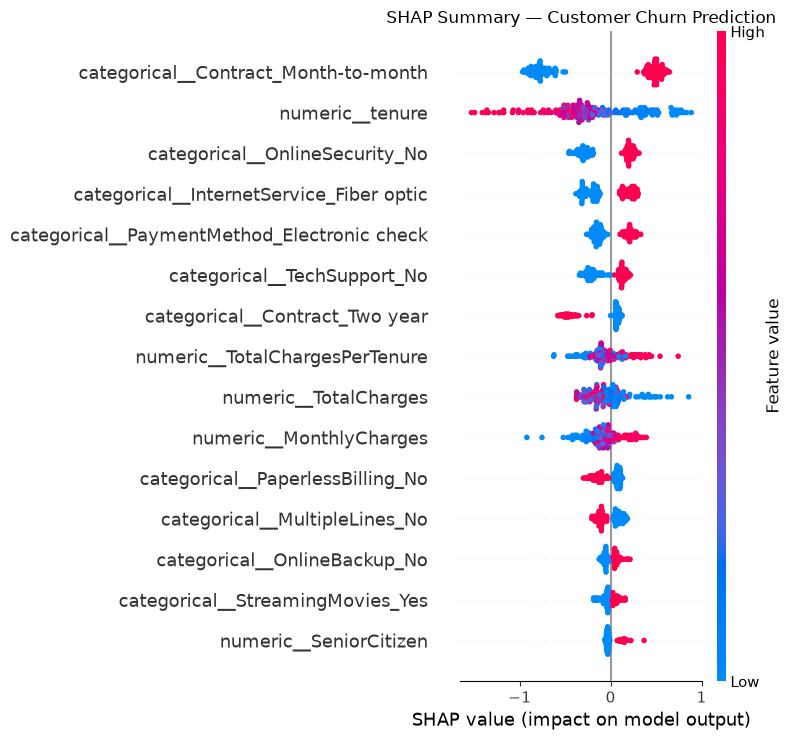

In [46]:
import shap
import matplotlib.pyplot as plt

# Get the fitted preprocessing and XGBoost model
xgb_pipeline = all_models["XGBoost"]

preprocessor_fitted = xgb_pipeline.named_steps["preprocessing"]
xgb_model = xgb_pipeline.named_steps["model"]

# Transform a sample of test customers
X_sample = X_test.sample(
    n=min(200, len(X_test)),
    random_state=42
)

X_transformed = preprocessor_fitted.transform(X_sample)

# Get feature names after preprocessing
feature_names = preprocessor_fitted.get_feature_names_out()

# Create SHAP explainer
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_transformed)

# Plot the most important features
shap.summary_plot(
    shap_values,
    X_transformed,
    feature_names=feature_names,
    max_display=15,
    show=False
)

plt.title("SHAP Summary — Customer Churn Prediction")
plt.tight_layout()
plt.show()

In [47]:
import joblib
from pathlib import Path

# Create a folder for saved models
model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

# Save the complete XGBoost pipeline
joblib.dump(
    all_models["XGBoost"],
    model_dir / "churn_model.joblib"
)

print("Model saved successfully!")
print("Location:", model_dir / "churn_model.joblib")

Model saved successfully!
Location: models\churn_model.joblib


In [48]:
from pathlib import Path

requirements = """pandas
numpy
matplotlib
seaborn
scikit-learn
xgboost
shap
joblib
"""

Path("requirements.txt").write_text(
    requirements,
    encoding="utf-8"
)

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [49]:

from pathlib import Path

readme = """# Customer Churn Prediction — ConnectTel

## 1. Project Overview

This project predicts whether a telecom customer is likely to leave the company (churn). It uses machine learning to identify important churn patterns and support customer-retention strategies.

## 2. Objectives

- Explore customer data and identify churn patterns.
- Perform data cleaning and feature engineering.
- Train and compare Logistic Regression, Random Forest, and XGBoost.
- Evaluate models using Accuracy, Precision, Recall, and ROC-AUC.
- Use SHAP to understand important prediction features.
- Save the trained model for future use.

## 3. Dataset

The project uses the Telco Customer Churn dataset from Kaggle.

Expected CSV location:

`data/archive/WA_Fn-UseC_-Telco-Customer-Churn.csv`

The dataset contains 7,043 customer records. Blank values in `TotalCharges` were converted to numeric values; 11 records with zero tenure had their missing `TotalCharges` set to 0.

## 4. Feature Engineering

Three additional features were created:

- `TotalChargesPerTenure`
- `ServiceCount`
- `HasMultipleServices`

## 5. Models and Test Results

| Model | Accuracy | Precision | Recall | ROC-AUC |
|---|---:|---:|---:|---:|
| Logistic Regression | 0.743 | 0.510 | 0.791 | 0.842 |
| Random Forest | 0.759 | 0.541 | 0.612 | 0.822 |
| XGBoost | 0.806 | 0.669 | 0.535 | 0.845 |

XGBoost achieved the highest ROC-AUC among these tested models. Logistic Regression achieved higher recall, which may be useful when identifying as many potential churners as possible.

## 6. Model Interpretation

SHAP was used to examine which features influence XGBoost predictions. Important features included contract type, tenure, online security, internet service type, payment method, and technical support.

Feature importance indicates associations in model predictions; it does not establish causation.

## 7. Project Structure

- `01_Data_Exploration.ipynb` — data exploration, preprocessing, feature engineering, model training, evaluation, and SHAP analysis.
- `data/archive/` — source dataset.
- `models/churn_model.joblib` — saved XGBoost pipeline.
- `Business_Insights_Report.md` — business findings and recommendations.
- `requirements.txt` — Python package dependencies.
- `README.md` — project documentation.

## 8. Setup and Usage

Use Python 3.12 or a compatible Python environment.

Install dependencies:

```bash
pip install -r requirements.txt
```

Launch Jupyter Notebook:

```bash
jupyter notebook
```

Open `01_Data_Exploration.ipynb` and run the cells in order.

## 9. Limitations

- Results depend on the dataset and its representativeness.
- Model performance may change with new customer data.
- A high churn-risk prediction does not guarantee that a customer will leave.
- This project is currently a local machine-learning project; a public prediction API and deployed web interface are separate deployment steps.

## 10. Future Improvements

- Tune and validate models more extensively.
- Evaluate business costs associated with missed churners and false alarms.
- Build a prediction API and interactive web interface.
- Containerize and deploy the application.

## 11. Disclaimer

This project is for educational and analytical purposes. Predictions should support, not replace, business judgment.
"""

Path("README.md").write_text(readme, encoding="utf-8")
print("README.md created successfully!")
print("Location:", Path("README.md").resolve())


README.md created successfully!
Location: C:\CustomerChurnPredictor\README.md


In [50]:

import joblib
from pathlib import Path
import pandas as pd

model_path = Path("models/churn_model.joblib")

# Load the saved model
loaded_model = joblib.load(model_path)

# Select one customer from the test dataset
sample_customer = X_test.iloc[[0]]

# Generate prediction and churn probability
prediction = loaded_model.predict(sample_customer)[0]
probability = loaded_model.predict_proba(sample_customer)[0][1]

print("Model loaded successfully!")
print("Predicted churn:", "Yes" if prediction == 1 else "No")
print(f"Churn probability: {probability:.2%}")


Model loaded successfully!
Predicted churn: No
Churn probability: 1.33%


In [51]:
import joblib
import numpy as np

loaded_model = joblib.load("models/churn_model.joblib")

# Predict churn for the entire test dataset
predictions = loaded_model.predict(X_test)
probabilities = loaded_model.predict_proba(X_test)[:, 1]

print("Number of test customers:", len(X_test))
print("Predictions generated:", len(predictions))
print("All probabilities are valid:",
      np.all((probabilities >= 0) & (probabilities <= 1)))
print("Predicted churn cases:", int((predictions == 1).sum()))
print("Predicted non-churn cases:", int((predictions == 0).sum()))

Number of test customers: 1409
Predictions generated: 1409
All probabilities are valid: True
Predicted churn cases: 299
Predicted non-churn cases: 1110
